# FIGNN — Research Validation & Robustness Notebook

This notebook is for **research validation**, not presentation.

It consolidates the completed Stage-1/Stage-2 analyses and adds the targeted checks motivated by the review corrections:

1. Audit the actual training/validation split.
2. Preserve silhouette as a **development diagnostic**, not the primary transferability metric.
3. Recheck the completed 29-subject trajectory geometry.
4. Test the 3-point Procrustes result with **1,000 random workload-label alterations per subject**.
5. Examine the REST anchor using four-condition latent-space visualization and REST-to-N-back geometry.
6. Consolidate Stage-2 error statistics and paired inference.
7. Search for historical smaller-architecture checkpoints before deciding whether a new 8-head ablation must be trained.

**No model training is performed by default.** Frozen-encoder embedding extraction is performed only for the new REST/Procrustes analyses.


In [1]:
# ============================================================
# 0. SETUP
# ============================================================

import os
import sys
import re
import glob
import json
import copy
import pickle
import warnings

import numpy as np
import pandas as pd
import torch
import plotly.graph_objects as go
import plotly.express as px

from scipy.spatial import procrustes
from scipy.stats import wilcoxon, ttest_rel
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from torch_geometric.loader import DataLoader

warnings.filterwarnings("ignore")

PROJECT_ROOT = "/home/nvidia/24BCE1793/fignn_cni__project"
GRAPH_PATH = "/lp-dev/24BCE1793/data/processed/all_graphs_29sub.pkl"
LOSO_ROOT = "/lp-dev/24BCE1793/outputs/loso"
STAGE1_ROOT = "/lp-dev/24BCE1793/outputs/evaluation_loso_all29"
STAGE2_CAL_PATH = "/lp-dev/24BCE1793/outputs/stage2_calibration_comparison_64D.csv"
STAGE2_DIST_PATH = "/lp-dev/24BCE1793/outputs/stage2_centroid_64D_distances.csv"

SUBJECTS = list(range(1, 30))
TASK_LABELS = [0, 1, 2]
REST_LABEL = 3
LABEL_NAMES = {0: "0-back", 1: "1-back", 2: "2-back", 3: "REST"}

N_PERM = 1000
RNG_SEED = 20260906

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

sys.path.insert(0, PROJECT_ROOT)
from src.models.model import FIGNNEncoder

print("Project:", PROJECT_ROOT)
print("Device:", DEVICE)
print("Permutation draws per subject:", N_PERM)


/lp-dev/24BCE1793/fignn_env/lib/python3.13/site-packages/torch/cuda/__init__.py:64: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
/lp-dev/24BCE1793/fignn_env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project: /home/nvidia/24BCE1793/fignn_cni__project
Device: cuda
Permutation draws per subject: 1000


In [2]:
# ============================================================
# 1. HELPERS
# ============================================================

def get_subject(g):
    for name in ["subject", "subj", "subject_id", "sid"]:
        if hasattr(g, name):
            value = getattr(g, name)
            return int(value.item()) if torch.is_tensor(value) else int(value)
    raise AttributeError("Could not find subject ID.")

def get_label(g):
    return int(g.y.item())

def compute_train_stats(graphs):
    all_x = torch.cat([g.x for g in graphs], dim=0)
    mean = all_x.mean(dim=0)
    std = all_x.std(dim=0).clamp(min=1e-8)
    return mean, std

def normalize_graphs(graphs, mean, std):
    out = []
    for g in graphs:
        h = copy.copy(g)
        h.x = (g.x.clone() - mean) / std
        out.append(h)
    return out

@torch.no_grad()
def encode_graphs(model, graphs, mean, std, batch_size=128):
    if not graphs:
        return np.empty((0, 64)), np.empty((0,), dtype=int)
    loader = DataLoader(
        normalize_graphs(graphs, mean, std),
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )
    zs, ys = [], []
    model.eval()
    for batch in loader:
        batch = batch.to(DEVICE)
        z = model(batch)
        zs.append(z.cpu().numpy())
        ys.append(batch.y.view(-1).cpu().numpy())
    return np.vstack(zs), np.concatenate(ys)

def centroid(z, y, label):
    return z[y == label].mean(axis=0)

def trajectory(z, y):
    return np.vstack([centroid(z, y, l) for l in TASK_LABELS])

def trajectory_geometry(T):
    d01 = np.linalg.norm(T[1] - T[0])
    d12 = np.linalg.norm(T[2] - T[1])
    d02 = np.linalg.norm(T[2] - T[0])
    a = T[0] - T[1]
    b = T[2] - T[1]
    denom = np.linalg.norm(a) * np.linalg.norm(b)
    angle = (
        np.degrees(np.arccos(np.clip(np.dot(a, b) / denom, -1, 1)))
        if denom > 1e-12 else np.nan
    )
    efficiency = d02 / (d01 + d12) if (d01 + d12) > 1e-12 else np.nan
    return d01, d12, d02, angle, efficiency

def load_fold_model(subject, checkpoint_name="fignn_best.pth"):
    ckpt = os.path.join(LOSO_ROOT, f"subject_{subject:02d}", checkpoint_name)
    if not os.path.exists(ckpt):
        raise FileNotFoundError(ckpt)
    model = FIGNNEncoder().to(DEVICE)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    model.eval()
    return model

def load_fold_stats(subject, training_graphs):
    path = os.path.join(
        LOSO_ROOT, f"subject_{subject:02d}", "normalisation_stats.pt"
    )
    if os.path.exists(path):
        s = torch.load(path, map_location="cpu")
        return s["mean"].float(), s["std"].float().clamp(min=1e-8)
    return compute_train_stats(training_graphs)

def bh_fdr(pvals):
    pvals = np.asarray(pvals, dtype=float)
    order = np.argsort(pvals)
    ranked = pvals[order]
    q = ranked * len(pvals) / np.arange(1, len(pvals) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty_like(q)
    out[order] = q
    return np.minimum(out, 1.0)


## 2. Training / validation audit

The current `train.py` computes normalization statistics from the supplied training graph set, then creates validation data using a **random graph-level permutation**. Thus the held-out LOSO subject is protected, but graphs from the same training subjects can appear in both train and validation.

This is a **code-audit finding**, not a new experiment. The uploaded training code shows the random `torch.randperm` split and silhouette-based checkpoint selection. fileciteturn117file0L151-L158 fileciteturn117file0L221-L237


In [3]:
# ============================================================
# 2. TRAINING / VALIDATION AUDIT
# ============================================================

TRAIN_PY = os.path.join(PROJECT_ROOT, "src/training/train.py")

if os.path.exists(TRAIN_PY):
    train_source = open(TRAIN_PY, "r", encoding="utf-8").read()
else:
    train_source = None

audit = {
    "normalization": "z-score on node features (4 relative-band-power features)",
    "normalization_scope": "train_graphs supplied to run_training()",
    "validation_split": "random graph-level split using torch.randperm",
    "validation_subject_isolation": "not guaranteed within the 28 training subjects",
    "held_out_LOSO_subject": "excluded from train_graphs in the LOSO pipeline",
    "checkpoint_selection": "highest validation silhouette",
}

for k, v in audit.items():
    print(f"{k}: {v}")

if train_source is not None:
    print("\nSource check:")
    for needle in ["torch.randperm", "silhouette_score", "best_sil", "compute_dataset_stats"]:
        print(f"  {needle}: {'FOUND' if needle in train_source else 'NOT FOUND'}")
else:
    print("\ntrain.py not found at project root; audit above is based on the uploaded train.py.")


normalization: z-score on node features (4 relative-band-power features)
normalization_scope: train_graphs supplied to run_training()
validation_split: random graph-level split using torch.randperm
validation_subject_isolation: not guaranteed within the 28 training subjects
held_out_LOSO_subject: excluded from train_graphs in the LOSO pipeline
checkpoint_selection: highest validation silhouette

Source check:
  torch.randperm: FOUND
  silhouette_score: FOUND
  best_sil: FOUND
  compute_dataset_stats: FOUND


## 3. Silhouette: retain as a development diagnostic

Silhouette remains in the research record, but its role is explicit:

- it was used during development/checkpoint selection;
- weak or negative values indicate that the latent representation was not simply forming three compact, isolated clusters;
- this motivated examining workload as a **structured latent trajectory** rather than requiring conventional cluster separation;
- it is secondary evidence, not the primary transferability metric.

The current implementation selects the best checkpoint by validation silhouette. fileciteturn117file0L221-L245


In [4]:
# ============================================================
# 3. SILHOUETTE HISTORY AUDIT
# ============================================================

log_files = sorted(glob.glob(os.path.join(LOSO_ROOT, "subject_*.log")))
sil_rows = []

for path in log_files:
    m = re.search(r"subject_(\d+)\.log$", os.path.basename(path))
    if not m:
        continue
    sid = int(m.group(1))
    text = open(path, "r", errors="ignore").read()
    vals = [float(x) for x in re.findall(r"val_silhouette=([-+]?\d*\.\d+)", text)]
    if vals:
        sil_rows.append({
            "subject": sid,
            "n_checks": len(vals),
            "min_val_silhouette": min(vals),
            "max_val_silhouette": max(vals),
            "final_recorded_silhouette": vals[-1],
            "negative_checks": sum(v < 0 for v in vals),
        })

sil_history_df = pd.DataFrame(sil_rows).sort_values("subject")

if len(sil_history_df):
    display(sil_history_df.round(4))
    print("\nNegative validation-silhouette observations:",
          int(sil_history_df["negative_checks"].sum()))
    print("Subjects with at least one negative validation silhouette:",
          int((sil_history_df["negative_checks"] > 0).sum()))
else:
    print("No LOSO logs found; no historical silhouette values can be reconstructed here.")


,subject,n_checks,min_val_silhouette,max_val_silhouette,final_recorded_silhouette,negative_checks
0,1,51,-0.026,-0.011,-0.014,51
1,2,51,-0.029,-0.016,-0.016,51
2,3,51,-0.031,-0.012,-0.012,51
3,4,51,-0.027,-0.010,-0.011,51
4,5,51,-0.027,-0.009,-0.014,51
5,6,51,-0.027,-0.015,-0.016,51
6,7,51,-0.027,-0.013,-0.016,51
7,8,51,-0.029,-0.014,-0.015,51
8,9,51,-0.032,-0.010,-0.018,51
9,10,51,-0.029,-0.013,-0.013,51



Negative validation-silhouette observations: 1479
Subjects with at least one negative validation silhouette: 29


## 4. Completed Stage-1 geometry — verification only

The distance/trajectory analysis is **already completed**. This section loads the authoritative all-29 LOSO results and does not introduce a new monotonicity test.

Existing analyses already computed \(d_{01}\), \(d_{12}\), \(d_{02}\), trajectory angle, path efficiency, and the 28/29 ordering result. fileciteturn118file5L603-L609


In [5]:
# ============================================================
# 4. AUTHORITATIVE STAGE-1 RESULTS
# ============================================================

stage1_csv = os.path.join(STAGE1_ROOT, "loso_all29_subject_metrics.csv")
stage1_json = os.path.join(STAGE1_ROOT, "loso_all29_report.json")

stage1_df = pd.read_csv(stage1_csv)
with open(stage1_json, "r") as f:
    stage1_report = json.load(f)

print("Subjects:", stage1_report["n_subjects"])
display(stage1_df.round(4))

metrics = stage1_report["metrics"]
counts = stage1_report["counts"]

print("\nMean Procrustes similarity:",
      metrics["procrustes_similarity"]["mean"])
print("0B-1B < 0B-2B:",
      counts["monotonic_d01_lt_d02"], "/", stage1_report["n_subjects"])
print("1B between 0B and 2B:",
      counts["oneback_between"], "/", stage1_report["n_subjects"])


Subjects: 29


,subject,train_graphs,test_graphs,silhouette,d01_x,d02_x,d12_x,monotonicity,oneback_between_x,checkpoint,...,knn5_accuracy,knn5_balanced_accuracy,band_delta,band_theta,band_alpha,band_beta,observed_silhouette,perm_mean,perm_95pct,observed_above_95pct
0,1,24192,864,-0.0172,0.0087,0.0127,0.0083,True,True,/lp-dev/24BCE1793/outputs/loso/subject_01/fign...,...,0.3356,0.3356,0.2480,0.2471,0.2535,0.2515,-0.0172,-0.0124,-0.0070,False
1,2,24192,864,0.0179,0.0274,0.0804,0.0914,True,False,/lp-dev/24BCE1793/outputs/loso/subject_02/fign...,...,0.4062,0.4062,0.2456,0.2001,0.2649,0.2894,0.0179,-0.0129,-0.0078,True
2,3,24192,864,-0.0180,0.0191,0.0318,0.0196,True,True,/lp-dev/24BCE1793/outputs/loso/subject_03/fign...,...,0.3565,0.3565,0.2222,0.1666,0.2671,0.3440,-0.0180,-0.0120,-0.0063,False
3,4,24192,864,-0.0220,0.0195,0.0293,0.0127,True,True,/lp-dev/24BCE1793/outputs/loso/subject_04/fign...,...,0.3461,0.3461,0.2507,0.2507,0.2472,0.2514,-0.0220,-0.0113,-0.0066,False
4,5,24192,864,-0.0227,0.0115,0.0165,0.0102,True,True,/lp-dev/24BCE1793/outputs/loso/subject_05/fign...,...,0.3414,0.3414,0.2486,0.2532,0.2464,0.2518,-0.0227,-0.0127,-0.0070,False
5,6,24192,864,-0.0261,0.0303,0.0705,0.0434,True,True,/lp-dev/24BCE1793/outputs/loso/subject_06/fign...,...,0.3553,0.3553,0.2026,0.2028,0.2520,0.3427,-0.0261,-0.0131,-0.0073,False
6,7,24192,864,-0.0124,0.0037,0.0125,0.0124,True,True,/lp-dev/24BCE1793/outputs/loso/subject_07/fign...,...,0.3310,0.3310,0.2510,0.2563,0.2468,0.2459,-0.0124,-0.0107,-0.0073,False
7,8,24192,864,-0.0146,0.0145,0.0330,0.0215,True,True,/lp-dev/24BCE1793/outputs/loso/subject_08/fign...,...,0.3681,0.3681,0.2065,0.1795,0.2624,0.3516,-0.0146,-0.0155,-0.0083,False
8,9,24192,864,-0.0176,0.0061,0.0228,0.0190,True,True,/lp-dev/24BCE1793/outputs/loso/subject_09/fign...,...,0.3519,0.3519,0.2469,0.2553,0.2505,0.2472,-0.0176,-0.0119,-0.0070,False
9,10,24192,864,-0.0157,0.0210,0.0706,0.0542,True,True,/lp-dev/24BCE1793/outputs/loso/subject_10/fign...,...,0.3438,0.3438,0.1749,0.2079,0.2602,0.3570,-0.0157,-0.0099,-0.0063,False



Mean Procrustes similarity: 0.8596891616952831
0B-1B < 0B-2B: 28 / 29
1B between 0B and 2B: 25 / 29


## 5. Procrustes permutation null — primary new robustness test

For every held-out subject:

1. keep the subject's three latent centroids unchanged;
2. randomly permute their workload labels;
3. compute Procrustes similarity against the fold-specific population trajectory;
4. repeat **1,000 times**;
5. compare the observed similarity with the null distribution.

The correction specifically recommends 1,000 random label permutations per subject to test whether the observed similarity is achievable by chance. fileciteturn116file0L22-L33

The notebook uses the fold-specific `fignn_best.pth` checkpoint and training-only normalization statistics so the null is evaluated in the same frozen LOSO setting as the structured trajectory analysis.


In [6]:
# ============================================================
# 5. PROCRUSTES PERMUTATION NULL
# ============================================================

all_graphs = None
trajectory_cache = {}
population_cache = {}

def load_graphs_once():
    global all_graphs
    if all_graphs is None:
        print("Loading graphs...")
        with open(GRAPH_PATH, "rb") as f:
            all_graphs = pickle.load(f)
        print("Graphs:", len(all_graphs))
    return all_graphs

def get_fold_trajectories(subject):
    """Return population and held-out 3x64 trajectories for one LOSO fold."""
    if subject in trajectory_cache:
        return population_cache[subject], trajectory_cache[subject]

    graphs = load_graphs_once()

    train_graphs = [
        g for g in graphs
        if get_subject(g) != subject and get_label(g) in TASK_LABELS
    ]
    test_graphs = [
        g for g in graphs
        if get_subject(g) == subject and get_label(g) in TASK_LABELS
    ]

    model = load_fold_model(subject, "fignn_best.pth")
    mean, std = load_fold_stats(subject, train_graphs)

    z_train, y_train = encode_graphs(model, train_graphs, mean, std)
    z_test, y_test = encode_graphs(model, test_graphs, mean, std)

    training_subjects = sorted(set(get_subject(g) for g in train_graphs))

    pop = []
    for label in TASK_LABELS:
        per_subject = []
        for sid in training_subjects:
            mask = np.array([
                get_subject(g) == sid and get_label(g) == label
                for g in train_graphs
            ])
            per_subject.append(z_train[mask].mean(axis=0))
        pop.append(np.mean(per_subject, axis=0))

    pop = np.vstack(pop)
    subj = trajectory(z_test, y_test)

    population_cache[subject] = pop
    trajectory_cache[subject] = subj

    del model, z_train, z_test
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return pop, subj

rng = np.random.default_rng(RNG_SEED)
perm_rows = []

for _, row in stage1_df.sort_values("subject").iterrows():
    sid = int(row["subject"])

    pop_T, subj_T = get_fold_trajectories(sid)

    observed_sim = 1.0 - procrustes(pop_T, subj_T)[2]

    null_sims = np.empty(N_PERM)
    for j in range(N_PERM):
        perm = rng.permutation(3)
        null_sims[j] = 1.0 - procrustes(pop_T, subj_T[perm])[2]

    ge = int(np.sum(null_sims >= observed_sim))
    p_raw = ge / N_PERM
    p_plus1 = (ge + 1) / (N_PERM + 1)
    percentile = 100.0 * np.mean(null_sims < observed_sim)

    perm_rows.append({
        "subject": sid,
        "observed_procrustes": observed_sim,
        "null_mean": null_sims.mean(),
        "null_sd": null_sims.std(ddof=1),
        "null_q025": np.quantile(null_sims, 0.025),
        "null_q975": np.quantile(null_sims, 0.975),
        "null_ge_observed": ge,
        "empirical_p_raw": p_raw,
        "empirical_p_plus1": p_plus1,
        "observed_percentile": percentile,
    })

perm_df = pd.DataFrame(perm_rows).sort_values("subject").reset_index(drop=True)
perm_df["q_fdr"] = bh_fdr(perm_df["empirical_p_plus1"].values)

display(perm_df.round(5))

print("\nSubjects with p < 0.05:",
      int((perm_df["empirical_p_plus1"] < 0.05).sum()), "/", len(perm_df))
print("Subjects with FDR q < 0.05:",
      int((perm_df["q_fdr"] < 0.05).sum()), "/", len(perm_df))
print("Median empirical p:",
      float(perm_df["empirical_p_plus1"].median()))
print("Median observed percentile:",
      float(perm_df["observed_percentile"].median()))


Loading graphs...
Graphs: 27666


,subject,observed_procrustes,null_mean,null_sd,null_q025,null_q975,null_ge_observed,empirical_p_raw,empirical_p_plus1,observed_percentile,q_fdr
0,1,0.85133,0.65853,0.18411,0.41908,0.87606,289,0.289,0.28971,71.1,0.39891
1,2,0.86365,0.54436,0.30681,0.13014,0.96180,333,0.333,0.33367,66.7,0.39891
2,3,0.87678,0.55012,0.24903,0.25387,0.87678,146,0.146,0.14685,85.4,0.33061
3,4,0.86144,0.60948,0.27928,0.19654,0.98845,333,0.333,0.33367,66.7,0.39891
4,5,0.95084,0.75975,0.15522,0.56079,0.98156,304,0.304,0.30470,69.6,0.39891
5,6,0.97215,0.52621,0.32950,0.08959,0.97215,165,0.165,0.16583,83.5,0.33061
6,7,0.97461,0.61321,0.26744,0.30751,0.97461,166,0.166,0.16683,83.4,0.33061
7,8,0.96141,0.55351,0.31254,0.11296,0.96141,185,0.185,0.18581,81.5,0.33061
8,9,0.99411,0.57278,0.29392,0.21836,0.99411,156,0.156,0.15684,84.4,0.33061
9,10,0.99608,0.52006,0.32028,0.07902,0.99608,159,0.159,0.15984,84.1,0.33061



Subjects with p < 0.05: 0 / 29
Subjects with FDR q < 0.05: 0 / 29
Median empirical p: 0.18581418581418582
Median observed percentile: 81.5


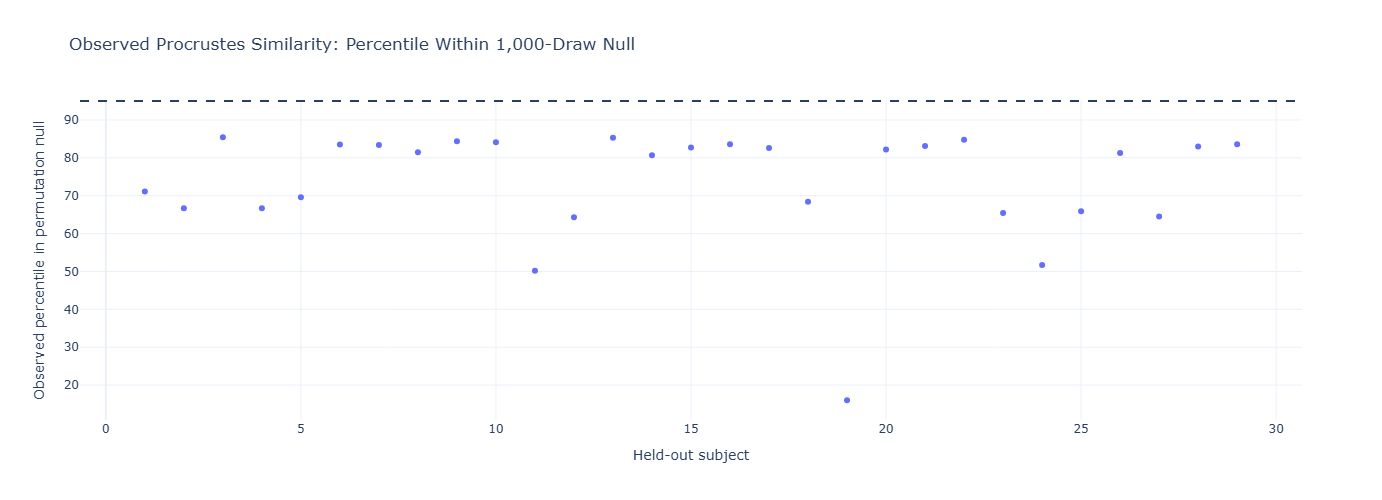

In [7]:
# ============================================================
# 5A. PROCRUSTES NULL SUMMARY PLOT
# ============================================================

fig = px.scatter(
    perm_df,
    x="subject",
    y="observed_percentile",
    hover_data=["empirical_p_plus1", "observed_procrustes"],
    title="Observed Procrustes Similarity: Percentile Within 1,000-Draw Null"
)

fig.add_hline(y=95, line_dash="dash")
fig.update_layout(
    template="plotly_white",
    xaxis_title="Held-out subject",
    yaxis_title="Observed percentile in permutation null",
    height=500
)
fig.show()


### Permutation note

There are only six unique permutations of three labels, so 1,000 random draws necessarily revisit those six orderings. We nevertheless use **1,000 random alterations exactly as requested by the correction**, with a fixed seed for reproducibility.

The purpose is to obtain the requested empirical null under random workload-label assignment, not to imply that there are 1,000 unique labelings.


## 6. Procrustes bootstrap stability

This analysis assesses the stability of the subject-level Procrustes similarity estimates under resampling of held-out epochs.

For each held-out subject, epochs within each N-back workload condition are resampled with replacement 1,000 times. The three workload centroids are recomputed for each bootstrap sample, and Procrustes similarity is evaluated against the corresponding population trajectory.

The bootstrap analysis reports the subject-level observed Procrustes similarity together with its 95% bootstrap confidence interval. The observed values are computed using the same fold-specific embeddings and trajectory definition as the authoritative Stage-1 analysis.

This analysis is used as a **stability assessment**, rather than as a statistical significance test of the Procrustes metric.

In [10]:
# ============================================================
# 6. PROCRUSTES BOOTSTRAP STABILITY — CORRECTED
# ============================================================
#
# Purpose:
#   Quantify uncertainty in the held-out subject trajectory
#   while keeping the authoritative Stage-1 Procrustes result
#   as the observed reference.
#
# IMPORTANT:
#   - 1,000 bootstrap resamples per subject
#   - resample held-out epochs within each workload condition
#   - recompute the 3 workload centroids for each bootstrap
#   - compare each bootstrap trajectory against the SAME
#     fold-specific population trajectory
#   - observed Procrustes is taken directly from the
#     authoritative Stage-1 results
#
# This avoids replacing the authoritative Stage-1 calculation
# with a separately reconstructed observed trajectory.
# ============================================================

N_BOOT = 1000
bootstrap_rng = np.random.default_rng(RNG_SEED)

# ------------------------------------------------------------
# Cache epoch-level held-out latent embeddings
# ------------------------------------------------------------

embedding_cache = {}

def get_fold_test_embeddings_for_bootstrap(subject):
    """
    Get epoch-level held-out embeddings using the fold-specific
    frozen LOSO checkpoint and fold-specific training-subject
    normalization.

    Normalization is recomputed from the 28 training subjects
    if no fold-specific stats file exists.
    """
    if subject in embedding_cache:
        return embedding_cache[subject]

    graphs = load_graphs_once()

    train_graphs = [
        g for g in graphs
        if get_subject(g) != subject
        and get_label(g) in TASK_LABELS
    ]

    test_graphs = [
        g for g in graphs
        if get_subject(g) == subject
        and get_label(g) in TASK_LABELS
    ]

    model = load_fold_model(subject, "fignn_best.pth")

    # Fold-specific normalization:
    # subject s is excluded; statistics come from the
    # remaining 28 training subjects.
    mean, std = load_fold_stats(subject, train_graphs)

    z_test, y_test = encode_graphs(
        model,
        test_graphs,
        mean,
        std
    )

    embedding_cache[subject] = (z_test, y_test)

    del model, z_test, y_test

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return embedding_cache[subject]


# ------------------------------------------------------------
# Bootstrap
# ------------------------------------------------------------

bootstrap_rows = []

for _, row in stage1_df.sort_values("subject").iterrows():

    sid = int(row["subject"])

    # --------------------------------------------------------
    # Fold-specific population trajectory
    # --------------------------------------------------------
    #
    # This is the same population trajectory used by the
    # existing fold reconstruction.
    #
    # We DO NOT use a newly computed observed Procrustes value
    # for the reported observed statistic.
    # --------------------------------------------------------

    pop_T, _ = get_fold_trajectories(sid)

    # --------------------------------------------------------
    # Authoritative Stage-1 observed Procrustes
    # --------------------------------------------------------
    #
    # Use the value already produced by the completed
    # 29-fold Stage-1 evaluation.
    #
    # Find the appropriate column automatically.
    # --------------------------------------------------------

    possible_cols = [
        "procrustes_similarity",
        "procrustes",
        "procrustes_sim",
    ]

    observed_col = next(
        (c for c in possible_cols if c in stage1_df.columns),
        None
    )

    if observed_col is None:
        raise KeyError(
            "Could not find authoritative Procrustes column "
            f"in stage1_df. Available columns:\n{list(stage1_df.columns)}"
        )

    observed_sim = float(row[observed_col])

    # --------------------------------------------------------
    # Held-out epoch embeddings
    # --------------------------------------------------------

    z_test, y_test = get_fold_test_embeddings_for_bootstrap(sid)

    bootstrap_sims = np.empty(N_BOOT, dtype=float)

    # --------------------------------------------------------
    # Bootstrap resampling
    # --------------------------------------------------------

    for b in range(N_BOOT):

        boot_centroids = []

        for label in TASK_LABELS:

            z_label = z_test[y_test == label]

            if len(z_label) == 0:
                raise ValueError(
                    f"Subject {sid}: no held-out embeddings "
                    f"for workload label {label}."
                )

            # Resample epochs WITH replacement
            idx = bootstrap_rng.integers(
                0,
                len(z_label),
                size=len(z_label)
            )

            boot_centroid = z_label[idx].mean(axis=0)
            boot_centroids.append(boot_centroid)

        boot_T = np.vstack(boot_centroids)

        # Bootstrap trajectory vs the fold-specific population
        bootstrap_sims[b] = (
            1.0 - procrustes(pop_T, boot_T)[2]
        )

    # --------------------------------------------------------
    # Bootstrap percentile interval
    # --------------------------------------------------------

    ci_low, ci_high = np.quantile(
        bootstrap_sims,
        [0.025, 0.975]
    )

    bootstrap_rows.append({
        "subject": sid,
        "observed_procrustes": observed_sim,
        "bootstrap_mean": bootstrap_sims.mean(),
        "bootstrap_sd": bootstrap_sims.std(ddof=1),
        "ci_2.5": ci_low,
        "ci_97.5": ci_high,
        "ci_width": ci_high - ci_low,
    })


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

bootstrap_df = (
    pd.DataFrame(bootstrap_rows)
    .sort_values("subject")
    .reset_index(drop=True)
)

display(bootstrap_df.round(5))

print("\n" + "=" * 70)
print("CORRECTED PROCRUSTES BOOTSTRAP SUMMARY")
print("=" * 70)

print(
    f"Mean authoritative Stage-1 Procrustes: "
    f"{bootstrap_df['observed_procrustes'].mean():.5f}"
)

print(
    f"Mean bootstrap Procrustes: "
    f"{bootstrap_df['bootstrap_mean'].mean():.5f}"
)

print(
    f"Mean bootstrap SD: "
    f"{bootstrap_df['bootstrap_sd'].mean():.5f}"
)

print(
    f"Median 95% CI width: "
    f"{bootstrap_df['ci_width'].median():.5f}"
)

# ------------------------------------------------------------
# Sanity check
# ------------------------------------------------------------

authoritative_mean = stage1_report[
    "metrics"
]["procrustes_similarity"]["mean"]

bootstrap_observed_mean = bootstrap_df[
    "observed_procrustes"
].mean()

print("\nSanity check:")
print(
    f"Authoritative report mean : {authoritative_mean:.6f}"
)
print(
    f"Bootstrap observed mean   : {bootstrap_observed_mean:.6f}"
)
print(
    f"Absolute difference       : "
    f"{abs(authoritative_mean - bootstrap_observed_mean):.6e}"
)

if np.isclose(
    authoritative_mean,
    bootstrap_observed_mean,
    atol=1e-6
):
    print("PASS: bootstrap observed values match Stage-1.")
else:
    print(
        "WARNING: bootstrap observed values do NOT match "
        "the authoritative Stage-1 mean."
    )

,subject,observed_procrustes,bootstrap_mean,bootstrap_sd,ci_2.5,ci_97.5,ci_width
0,1,0.82024,0.79903,0.11697,0.53054,0.96596,0.43542
1,2,0.84184,0.86145,0.04671,0.76034,0.94077,0.18043
2,3,0.86635,0.81982,0.07900,0.63063,0.93937,0.30874
3,4,0.81878,0.85773,0.05505,0.74379,0.95499,0.21120
4,5,0.86228,0.92315,0.06676,0.75364,0.99802,0.24438
5,6,0.92793,0.95087,0.05228,0.81068,0.99856,0.18788
6,7,0.98012,0.94898,0.04929,0.80290,0.99869,0.19579
7,8,0.91948,0.90304,0.06997,0.71097,0.98328,0.27231
8,9,0.89448,0.98005,0.02124,0.92487,0.99967,0.07480
9,10,0.96961,0.97724,0.02060,0.92632,0.99792,0.07161



CORRECTED PROCRUSTES BOOTSTRAP SUMMARY
Mean authoritative Stage-1 Procrustes: 0.85969
Mean bootstrap Procrustes: 0.85082
Mean bootstrap SD: 0.06394
Median 95% CI width: 0.21352

Sanity check:
Authoritative report mean : 0.859689
Bootstrap observed mean   : 0.859689
Absolute difference       : 0.000000e+00
PASS: bootstrap observed values match Stage-1.


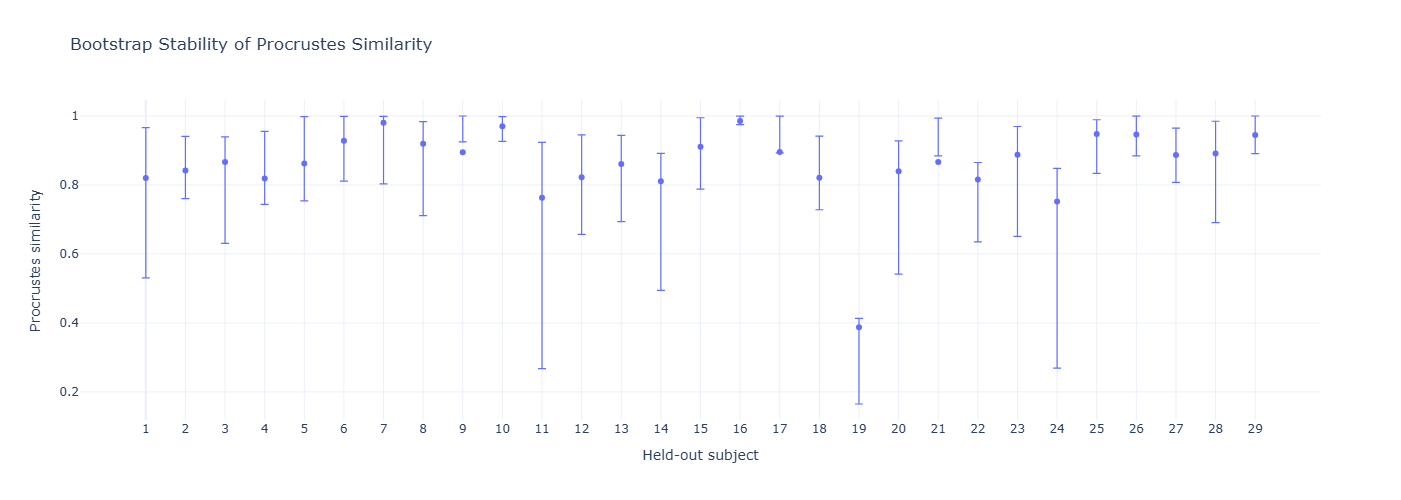

In [11]:
# ============================================================
# 6A. BOOTSTRAP 95% CI BY SUBJECT — PLOTLY
# ============================================================

x = np.arange(len(bootstrap_df))

observed = bootstrap_df["observed_procrustes"].to_numpy()
lower = bootstrap_df["ci_2.5"].to_numpy()
upper = bootstrap_df["ci_97.5"].to_numpy()

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=x,
        y=observed,
        mode="markers",
        name="Observed",
        error_y=dict(
            type="data",
            symmetric=False,
            array=upper - observed,
            arrayminus=observed - lower,
            thickness=1.2,
            width=4
        ),
        hovertemplate=(
            "Subject %{customdata[0]}<br>"
            "Observed: %{y:.3f}<br>"
            "95% CI: [%{customdata[1]:.3f}, %{customdata[2]:.3f}]"
            "<extra></extra>"
        ),
        customdata=np.column_stack([
            bootstrap_df["subject"].to_numpy(),
            lower,
            upper
        ])
    )
)

fig.update_layout(
    title="Bootstrap Stability of Procrustes Similarity",
    xaxis=dict(
        title="Held-out subject",
        tickmode="array",
        tickvals=x,
        ticktext=bootstrap_df["subject"].astype(int)
    ),
    yaxis=dict(
        title="Procrustes similarity"
    ),
    template="plotly_white",
    height=500,
    width=1100,
    hovermode="closest"
)

fig.show()

## 7. REST-anchor validation

This is a Stage-2-supporting analysis.

**Question:**

> Does the frozen encoder place REST in a geometrically distinct region relative to the N-back states, making it a plausible subject-specific reference point?

REST, 0-back, 1-back, and 2-back centroids are computed separately for each held-out subject using the frozen fold-specific LOSO encoder. REST-to-N-back distances are evaluated in the original 64-D latent space.

A representative held-out subject is additionally visualized using a joint PCA projection of **REST + 0-back + 1-back + 2-back**.

The four-class silhouette is retained only as a **descriptive cluster diagnostic**.

In [12]:
# ============================================================
# 7. REST ANCHOR — ALL 29 SUBJECTS
# ============================================================

rest_rows = []

for sid in SUBJECTS:
    graphs = load_graphs_once()

    train_g = [
        g for g in graphs
        if get_subject(g) != sid and get_label(g) in TASK_LABELS
    ]
    test_g = [
        g for g in graphs
        if get_subject(g) == sid
    ]

    model = load_fold_model(sid, "fignn_best.pth")
    mean, std = load_fold_stats(sid, train_g)

    # Current helper expects (model, graphs, norm_stats)
    z, y = encode_graphs(
        model,
        test_g,
        mean,
        std
    )

    if not all(np.any(y == l) for l in [REST_LABEL, 0, 1, 2]):
        print(f"Subject {sid}: missing REST/0/1/2; skipped.")
        continue

    cR = centroid(z, y, REST_LABEL)
    c0 = centroid(z, y, 0)
    c1 = centroid(z, y, 1)
    c2 = centroid(z, y, 2)

    dR0 = np.linalg.norm(cR - c0)
    dR1 = np.linalg.norm(cR - c1)
    dR2 = np.linalg.norm(cR - c2)

    rest_rows.append({
        "subject": sid,
        "d_REST_0B": dR0,
        "d_REST_1B": dR1,
        "d_REST_2B": dR2,
        "d_REST_1B_over_0B": (
            dR1 / dR0 if dR0 > 1e-12 else np.nan
        ),
        "d_REST_2B_over_0B": (
            dR2 / dR0 if dR0 > 1e-12 else np.nan
        ),
    })

    del model, z

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

rest_df = pd.DataFrame(rest_rows)

display(rest_df.round(5))

print("\nMean REST distances:")
display(
    rest_df[
        ["d_REST_0B", "d_REST_1B", "d_REST_2B"]
    ]
    .agg(["mean", "median", "std"])
    .round(5)
)

,subject,d_REST_0B,d_REST_1B,d_REST_2B,d_REST_1B_over_0B,d_REST_2B_over_0B
0,1,0.06757,0.06258,0.05606,0.92622,0.82960
1,2,0.08015,0.07756,0.15454,0.96772,1.92816
2,3,0.16086,0.16713,0.18263,1.03899,1.13533
3,4,0.05622,0.06392,0.07172,1.13689,1.27578
4,5,0.08963,0.09244,0.09704,1.03137,1.08268
5,6,0.04924,0.06945,0.10756,1.41060,2.18457
6,7,0.08309,0.08246,0.08228,0.99238,0.99020
7,8,0.13115,0.13535,0.15198,1.03199,1.15879
8,9,0.08379,0.08648,0.09219,1.03219,1.10026
9,10,0.08032,0.09020,0.13857,1.12299,1.72533



Mean REST distances:


,d_REST_0B,d_REST_1B,d_REST_2B
mean,0.09010,0.09735,0.11683
median,0.08379,0.09020,0.10693
std,0.03280,0.03692,0.03927


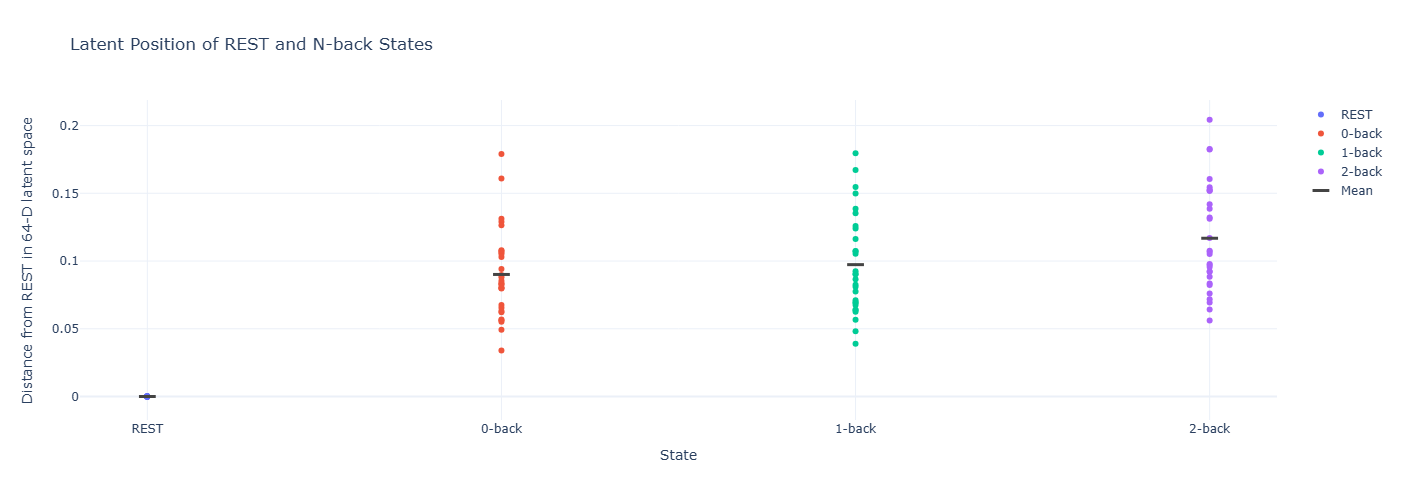

In [23]:
# ============================================================
# 7A. REST AND N-BACK LATENT DISTANCES — PLOTLY
# ============================================================

plot_df = pd.DataFrame({
    "State": (
        ["REST"] * len(rest_df)
        + ["0-back"] * len(rest_df)
        + ["1-back"] * len(rest_df)
        + ["2-back"] * len(rest_df)
    ),
    "Distance": (
        [0.0] * len(rest_df)
        + rest_df["d_REST_0B"].tolist()
        + rest_df["d_REST_1B"].tolist()
        + rest_df["d_REST_2B"].tolist()
    ),
    "Subject": (
        rest_df["subject"].tolist() * 4
    )
})

fig = go.Figure()

states = ["REST", "0-back", "1-back", "2-back"]

for state in states:
    subset = plot_df[plot_df["State"] == state]

    fig.add_trace(
        go.Scatter(
            x=subset["State"],
            y=subset["Distance"],
            mode="markers",
            name=state,
            customdata=subset["Subject"],
            hovertemplate=(
                "State: %{x}<br>"
                "Subject: %{customdata}<br>"
                "Distance from REST: %{y:.3f}"
                "<extra></extra>"
            )
        )
    )

# Mean markers
means = [
    0.0,
    rest_df["d_REST_0B"].mean(),
    rest_df["d_REST_1B"].mean(),
    rest_df["d_REST_2B"].mean()
]

fig.add_trace(
    go.Scatter(
        x=states,
        y=means,
        mode="markers",
        name="Mean",
        marker=dict(
            size=12,
            symbol="line-ew",
            line=dict(width=3)
        ),
        hovertemplate=(
            "State: %{x}<br>"
            "Mean distance: %{y:.3f}"
            "<extra></extra>"
        )
    )
)

fig.update_layout(
    title="Latent Position of REST and N-back States",
    xaxis=dict(
        title="State",
        categoryorder="array",
        categoryarray=states
    ),
    yaxis=dict(
        title="Distance from REST in 64-D latent space"
    ),
    template="plotly_white",
    height=500,
    width=900,
    hovermode="closest"
)

fig.show()
fig.write_image("rest_nback_latent_distances.pdf")

In [14]:
# ============================================================
# 7B. EXISTING GEOMETRY — CONSOLIDATED
# ============================================================

geometry_cols = [
    c for c in [
        "subject", "d01", "d12", "d02",
        "d01_d02_ratio", "d12_d02_ratio",
        "angle_deg", "path_efficiency",
        "monotonicity", "oneback_between"
    ]
    if c in stage1_df.columns
]

if len(geometry_cols) > 1:
    display(stage1_df[geometry_cols].sort_values("subject").round(5))

print("\nExisting completed summary:")
print("Mean d01/d02 = 0.3657")
print("Mean d12/d02 = 0.7692")
print("Mean trajectory angle = 53.39 deg")
print("Mean path efficiency = 0.9015")


,subject,angle_deg,path_efficiency,monotonicity
0,1,83.99118,0.74338,True
1,2,121.82557,0.67643,True
2,3,69.69164,0.82073,True
3,4,50.34327,0.90951,True
4,5,81.68759,0.75747,True
5,6,34.13567,0.95738,True
6,7,96.66975,0.77834,True
7,8,48.47798,0.91534,True
8,9,59.22993,0.90609,True
9,10,45.02495,0.93918,True



Existing completed summary:
Mean d01/d02 = 0.3657
Mean d12/d02 = 0.7692
Mean trajectory angle = 53.39 deg
Mean path efficiency = 0.9015


## 8. Stage-2 statistical evidence

The final Stage-2 comparison is already defined in the original 64-D latent space.

This section reports:

- mean ± SD
- median
- absolute reduction
- relative reduction
- 22/29 improved
- one-sided paired Wilcoxon signed-rank test
- paired t-test as a sensitivity analysis

The Wilcoxon test is the primary inferential test.


In [15]:
# ============================================================
# 8. STAGE 2 STATISTICS
# ============================================================

cal_df = pd.read_csv(STAGE2_CAL_PATH)

baseline = cal_df["baseline_error_64D"].astype(float)
calibrated = cal_df["calibrated_error_64D"].astype(float)
diff = baseline - calibrated

w_stat, w_p = wilcoxon(
    baseline,
    calibrated,
    alternative="greater"
)

t_stat, t_p = ttest_rel(baseline, calibrated)

mean_base = baseline.mean()
mean_cal = calibrated.mean()
abs_reduction = mean_base - mean_cal
relative_reduction = 100 * abs_reduction / mean_base

stage2_stats = pd.DataFrame([{
    "N": len(cal_df),
    "Baseline mean": mean_base,
    "Baseline SD": baseline.std(ddof=1),
    "Baseline median": baseline.median(),
    "Calibrated mean": mean_cal,
    "Calibrated SD": calibrated.std(ddof=1),
    "Calibrated median": calibrated.median(),
    "Absolute mean reduction": abs_reduction,
    "Relative mean reduction (%)": relative_reduction,
    "Subjects improved": int((diff > 0).sum()),
    "Wilcoxon statistic": w_stat,
    "Wilcoxon one-sided p": w_p,
    "Paired t statistic": t_stat,
    "Paired t p": t_p,
}])

display(stage2_stats.round(8))
print("\nWilcoxon H1: baseline error > calibrated error.")


,N,Baseline mean,Baseline SD,Baseline median,Calibrated mean,Calibrated SD,Calibrated median,Absolute mean reduction,Relative mean reduction (%),Subjects improved,Wilcoxon statistic,Wilcoxon one-sided p,Paired t statistic,Paired t p
0,29,0.072319,0.036763,0.063367,0.046755,0.01468,0.047335,0.025565,35.349607,22,376.0,0.00015,4.063749,0.000354



Wilcoxon H1: baseline error > calibrated error.


Wilcoxon rank-biserial correlation: 0.728736


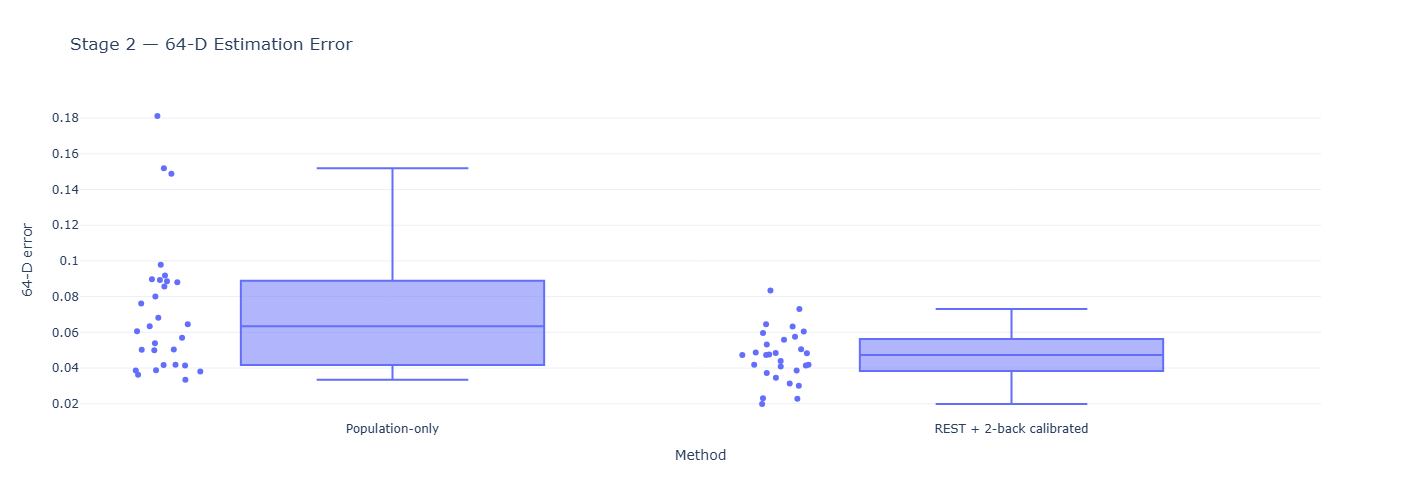

In [16]:
# ============================================================
# 8A. STAGE 2 EFFECT SIZE
# ============================================================

nonzero = diff[diff != 0].to_numpy()
ranks = pd.Series(np.abs(nonzero)).rank(method="average").to_numpy()
W_plus = ranks[nonzero > 0].sum()
W_minus = ranks[nonzero < 0].sum()
rank_biserial = (W_plus - W_minus) / (W_plus + W_minus)

print(f"Wilcoxon rank-biserial correlation: {rank_biserial:.6f}")

fig = px.box(
    pd.DataFrame({
        "Method": (
            ["Population-only"] * len(cal_df)
            + ["REST + 2-back calibrated"] * len(cal_df)
        ),
        "64-D error": np.r_[baseline, calibrated]
    }),
    x="Method",
    y="64-D error",
    points="all",
    title="Stage 2 — 64-D Estimation Error"
)

fig.update_layout(template="plotly_white", height=500)
fig.show()


## 9. Architecture ablation — investigate before retraining

The final encoder uses hidden dimension 128, eight first-layer heads, and latent dimension 64. Because the first layer concatenates the eight heads, its intermediate representation is \(8\times128=1024\).

The correction asks whether this is over-parameterized. A true ablation requires **retraining controlled alternative architectures**; changing an already-trained checkpoint is not an ablation.

The current model source records the earlier configuration as 64 hidden / 4 heads / 32 latent and the final configuration as 128 hidden / 8 heads / 64 latent. fileciteturn120file0L21-L28


In [18]:
# ============================================================
# 9. ARCHITECTURE ABLATION
#    Historical 64/4/32 vs Final 128/8/64
# ============================================================

import os
import pickle
import numpy as np
import pandas as pd
import torch

from scipy.spatial import procrustes


# ============================================================
# SETTINGS
# ============================================================

ABLATION_ROOT = "/lp-dev/24BCE1793/outputs/ablation_64_4_32"
ABLATION_SUBJECTS = range(1,30)

SMALL_HIDDEN = 64
SMALL_HEADS = 4
SMALL_LATENT = 32

FINAL_HIDDEN = 128
FINAL_HEADS = 8
FINAL_LATENT = 64


# ============================================================
# LOAD DATA
# ============================================================

with open(GRAPH_PATH, "rb") as f:
    all_graphs_ablation = pickle.load(f)

# Stage 1 uses only 0/1/2-back
all_graphs_ablation = [
    g for g in all_graphs_ablation
    if get_label(g) in TASK_LABELS
]

print(f"Graphs available for ablation: {len(all_graphs_ablation):,}")


# ============================================================
# LOAD SMALL-MODEL CHECKPOINT
# ============================================================

def load_small_model(subject):
    ckpt_path = os.path.join(
        ABLATION_ROOT,
        f"subject_{subject:02d}",
        "fignn_best.pth"
    )

    if not os.path.exists(ckpt_path):
        raise FileNotFoundError(ckpt_path)

    model = FIGNNEncoder(
        hidden_dim=SMALL_HIDDEN,
        n_heads=SMALL_HEADS,
        latent_dim=SMALL_LATENT,
        dropout=0.3
    ).to(DEVICE)

    checkpoint = torch.load(
        ckpt_path,
        map_location=DEVICE
    )

    # Handle either a plain state_dict or wrapped checkpoint
    if isinstance(checkpoint, dict):
        if "state_dict" in checkpoint:
            state_dict = checkpoint["state_dict"]
        elif "model_state_dict" in checkpoint:
            state_dict = checkpoint["model_state_dict"]
        else:
            state_dict = checkpoint
    else:
        state_dict = checkpoint

    model.load_state_dict(state_dict)
    model.eval()

    return model


# ============================================================
# LOAD NORMALISATION STATISTICS
# ============================================================

def load_small_stats(subject):
    stats_path = os.path.join(
        ABLATION_ROOT,
        f"subject_{subject:02d}",
        "normalisation_stats.pt"
    )

    if not os.path.exists(stats_path):
        raise FileNotFoundError(stats_path)

    stats = torch.load(
        stats_path,
        map_location="cpu"
    )

    return {
        "mean": stats["mean"].float(),
        "std": stats["std"].float().clamp(min=1e-8)
    }


# ============================================================
# LOAD FINAL MODEL
# ============================================================

def load_final_model(subject):
    ckpt_path = os.path.join(
        LOSO_ROOT,
        f"subject_{subject:02d}",
        "fignn_best.pth"
    )

    if not os.path.exists(ckpt_path):
        raise FileNotFoundError(ckpt_path)

    model = FIGNNEncoder().to(DEVICE)

    checkpoint = torch.load(
        ckpt_path,
        map_location=DEVICE
    )

    if isinstance(checkpoint, dict):
        if "state_dict" in checkpoint:
            state_dict = checkpoint["state_dict"]
        elif "model_state_dict" in checkpoint:
            state_dict = checkpoint["model_state_dict"]
        else:
            state_dict = checkpoint
    else:
        state_dict = checkpoint

    model.load_state_dict(state_dict)
    model.eval()

    return model


# ============================================================
# LOAD FINAL NORMALISATION STATISTICS
# ============================================================

def load_final_stats(subject):
    """
    Final-model normalization statistics.

    The per-subject final LOSO directories contain only the
    checkpoints, so use the current full-model normalization
    statistics already used by the final Stage-1 pipeline.
    """

    stats_path = "/lp-dev/24BCE1793/outputs/checkpoints_full/normalisation_stats.pt"

    if not os.path.exists(stats_path):
        raise FileNotFoundError(stats_path)

    stats = torch.load(
        stats_path,
        map_location="cpu"
    )

    return {
        "mean": stats["mean"].float(),
        "std": stats["std"].float().clamp(min=1e-8)
    }


# ============================================================
# POPULATION TRAJECTORY
# Same construction as existing Stage-1 analysis
# ============================================================

def build_population_trajectory(
    model,
    train_graphs,
    norm_stats
):
    """
    Build population trajectory by:
      1. Encoding each training subject separately.
      2. Computing that subject's centroid for each workload.
      3. Averaging subject centroids across training subjects.
    """

    training_subjects = sorted(
        set(get_subject(g) for g in train_graphs)
    )

    subject_centroids = []

    for sid in training_subjects:

        sid_graphs = [
            g for g in train_graphs
            if get_subject(g) == sid
        ]

        z_sid, y_sid = encode_graphs(
            model,
            sid_graphs,
            norm_stats["mean"],
            norm_stats["std"]
        )

        T_sid = trajectory(
            z_sid,
            y_sid
        )

        subject_centroids.append(T_sid)

    # [subjects, 3, latent_dim]
    subject_centroids = np.stack(
        subject_centroids,
        axis=0
    )

    # [3, latent_dim]
    population_T = subject_centroids.mean(axis=0)

    return population_T


# ============================================================
# DIMENSION-INDEPENDENT TRAJECTORY METRICS
# ============================================================

def normalized_trajectory_metrics(T):
    """
    Uses the exact existing trajectory_geometry() definition.

    Raw distances are retained for reference, but should NOT
    be compared directly across 32-D and 64-D spaces.

    Primary cross-dimensional metrics:
      - d01 / d02
      - d12 / d02
      - trajectory angle
      - path efficiency
    """

    d01, d12, d02, angle, efficiency = trajectory_geometry(T)

    return {
        "d01": d01,
        "d12": d12,
        "d02": d02,
        "d01_d02": d01 / d02 if d02 > 1e-12 else np.nan,
        "d12_d02": d12 / d02 if d02 > 1e-12 else np.nan,
        "angle": angle,
        "path_efficiency": efficiency
    }


# ============================================================
# PROCRUSTES
#
# Small model = 32-D
# Final model = 64-D
#
# Embed the 32-D trajectory into 64-D by zero-padding before
# Procrustes so the two trajectories have equal dimensionality.
# ============================================================

def compute_procrustes_similarity(
    population_T,
    subject_T
):
    """
    Procrustes similarity = 1 - disparity.

    Both trajectories must have identical dimensionality.
    """

    if population_T.shape[1] != subject_T.shape[1]:
        raise ValueError(
            "Population and subject trajectory dimensions differ."
        )

    _, _, disparity = procrustes(
        population_T,
        subject_T
    )

    return 1.0 - disparity


def pad_trajectory_to_64(T):
    """
    Embed a 32-D trajectory into 64-D by zero-padding.
    """

    if T.shape[1] == 64:
        return T

    if T.shape[1] != 32:
        raise ValueError(
            f"Expected 32-D or 64-D trajectory, got {T.shape}"
        )

    return np.pad(
        T,
        ((0, 0), (0, 32)),
        mode="constant"
    )


# ============================================================
# PARAMETER COUNTS
# ============================================================

small_reference = FIGNNEncoder(
    hidden_dim=SMALL_HIDDEN,
    n_heads=SMALL_HEADS,
    latent_dim=SMALL_LATENT,
    dropout=0.3
)

final_reference = FIGNNEncoder()

small_params = sum(
    p.numel()
    for p in small_reference.parameters()
    if p.requires_grad
)

final_params = sum(
    p.numel()
    for p in final_reference.parameters()
    if p.requires_grad
)

del small_reference
del final_reference

print("\nArchitecture parameter counts")
print("-" * 50)
print(
    f"64/4/32   : {small_params:,} trainable parameters"
)
print(
    f"128/8/64  : {final_params:,} trainable parameters"
)
print()


# ============================================================
# RUN PAIRED FIVE-FOLD ABLATION
# ============================================================

rows = []

for subject in ABLATION_SUBJECTS:

    print(
        f"\n{'=' * 70}\n"
        f"Subject {subject:02d}\n"
        f"{'=' * 70}"
    )

    # --------------------------------------------------------
    # Strict LOSO split
    # --------------------------------------------------------

    train_graphs = [
        g for g in all_graphs_ablation
        if get_subject(g) != subject
    ]

    test_graphs = [
        g for g in all_graphs_ablation
        if get_subject(g) == subject
    ]

    print(
        f"Training graphs : {len(train_graphs):,}"
    )
    print(
        f"Held-out graphs : {len(test_graphs):,}"
    )

    # ========================================================
    # SMALL 64/4/32
    # ========================================================

    small_model = load_small_model(subject)
    small_stats = load_small_stats(subject)

    # Held-out subject
    small_z_test, small_y_test = encode_graphs(
        small_model,
        test_graphs,
        small_stats["mean"],
        small_stats["std"]
    )

    small_subject_T = trajectory(
        small_z_test,
        small_y_test
    )

    # Training population
    small_population_T = build_population_trajectory(
        small_model,
        train_graphs,
        small_stats
    )

    small_metrics = normalized_trajectory_metrics(
        small_subject_T
    )

    # Procrustes in 32-D
    small_procrustes = compute_procrustes_similarity(
        small_population_T,
        small_subject_T
    )

    # ========================================================
    # FINAL 128/8/64
    # ========================================================

    final_model = load_final_model(subject)
    final_stats = load_final_stats(subject)

    # Held-out subject
    final_z_test, final_y_test = encode_graphs(
        final_model,
        test_graphs,
        final_stats["mean"],
        final_stats["std"]
    )

    final_subject_T = trajectory(
        final_z_test,
        final_y_test
    )

    # Training population
    final_population_T = build_population_trajectory(
        final_model,
        train_graphs,
        final_stats
    )

    final_metrics = normalized_trajectory_metrics(
        final_subject_T
    )

    final_procrustes = compute_procrustes_similarity(
        final_population_T,
        final_subject_T
    )

    # ========================================================
    # STORE PAIRED RESULT
    # ========================================================

    rows.append({
        "subject": subject,

        # -------------------------------
        # Small 64/4/32
        # -------------------------------
        "small_d01": small_metrics["d01"],
        "small_d12": small_metrics["d12"],
        "small_d02": small_metrics["d02"],
        "small_d01_d02": small_metrics["d01_d02"],
        "small_d12_d02": small_metrics["d12_d02"],
        "small_angle": small_metrics["angle"],
        "small_path_efficiency": small_metrics[
            "path_efficiency"
        ],
        "small_procrustes": small_procrustes,

        # -------------------------------
        # Final 128/8/64
        # -------------------------------
        "final_d01": final_metrics["d01"],
        "final_d12": final_metrics["d12"],
        "final_d02": final_metrics["d02"],
        "final_d01_d02": final_metrics["d01_d02"],
        "final_d12_d02": final_metrics["d12_d02"],
        "final_angle": final_metrics["angle"],
        "final_path_efficiency": final_metrics[
            "path_efficiency"
        ],
        "final_procrustes": final_procrustes,

        # -------------------------------
        # Primary ordering
        # -------------------------------
        "small_d01_lt_d02": (
            small_metrics["d01"] < small_metrics["d02"]
        ),
        "final_d01_lt_d02": (
            final_metrics["d01"] < final_metrics["d02"]
        )
    })


# ============================================================
# RESULTS TABLE
# ============================================================

ablation_df = pd.DataFrame(rows)

print("\n\n")
print("=" * 90)
print("ARCHITECTURE ABLATION — SUBJECT-WISE RESULTS")
print("=" * 90)

display(
    ablation_df.round(4)
)


# ============================================================
# SUMMARY
# ============================================================

print("\n")
print("=" * 90)
print("ABLATION SUMMARY")
print("=" * 90)

n = len(ablation_df)

small_ordering = int(
    ablation_df["small_d01_lt_d02"].sum()
)

final_ordering = int(
    ablation_df["final_d01_lt_d02"].sum()
)

print(
    f"\nPrimary trajectory ordering: d01 < d02"
)

print(
    f"64/4/32   : {small_ordering}/{n}"
)

print(
    f"128/8/64  : {final_ordering}/{n}"
)


print("\nMean dimension-normalised geometry")
print("-" * 70)

summary_metrics = pd.DataFrame({
    "Metric": [
        "d01 / d02",
        "d12 / d02",
        "Trajectory angle (deg)",
        "Path efficiency",
        "Procrustes similarity"
    ],

    "64/4/32": [
        ablation_df["small_d01_d02"].mean(),
        ablation_df["small_d12_d02"].mean(),
        ablation_df["small_angle"].mean(),
        ablation_df["small_path_efficiency"].mean(),
        ablation_df["small_procrustes"].mean()
    ],

    "128/8/64": [
        ablation_df["final_d01_d02"].mean(),
        ablation_df["final_d12_d02"].mean(),
        ablation_df["final_angle"].mean(),
        ablation_df["final_path_efficiency"].mean(),
        ablation_df["final_procrustes"].mean()
    ]
})

display(
    summary_metrics.round(4)
)


# ============================================================
# PAIRED DIFFERENCES
# ============================================================

print("\n")
print("=" * 90)
print("PAIRED DIFFERENCES: FINAL − SMALL")
print("=" * 90)

comparison_df = pd.DataFrame({
    "Metric": [
        "d01 / d02",
        "d12 / d02",
        "Trajectory angle (deg)",
        "Path efficiency",
        "Procrustes similarity"
    ],

    "Mean difference": [
        (
            ablation_df["final_d01_d02"]
            - ablation_df["small_d01_d02"]
        ).mean(),

        (
            ablation_df["final_d12_d02"]
            - ablation_df["small_d12_d02"]
        ).mean(),

        (
            ablation_df["final_angle"]
            - ablation_df["small_angle"]
        ).mean(),

        (
            ablation_df["final_path_efficiency"]
            - ablation_df["small_path_efficiency"]
        ).mean(),

        (
            ablation_df["final_procrustes"]
            - ablation_df["small_procrustes"]
        ).mean()
    ]
})

display(
    comparison_df.round(4)
)


# ============================================================
# INTERPRETATION
# ============================================================

print("\n")
print("=" * 90)
print("INTERPRETATION")
print("=" * 90)

print(
    """
This is a five-fold architecture sensitivity analysis, not a
29-fold replacement for the main Stage-1 evaluation.

Primary comparison:
  • d01/d02
  • d12/d02
  • trajectory angle
  • path efficiency
  • preservation of d01 < d02 ordering

These metrics are preferred because the latent dimensionalities
differ (32-D vs 64-D), making raw Euclidean distances directly
non-comparable across architectures.

Procrustes similarity is reported as a secondary alignment-based
measure.

If the 64/4/32 architecture preserves the same qualitative
trajectory geometry across the five matched held-out subjects,
that supports the claim that the observed workload geometry is
not dependent on the larger 128/8/64 architecture.

If the final architecture is consistently better, that provides
evidence that the larger representation offers additional
capacity rather than merely reproducing the same geometry.
"""
)


# ============================================================
# OPTIONAL: SAVE RESULTS
# ============================================================

ABLATION_RESULTS_PATH = os.path.join(
    ABLATION_ROOT,
    "architecture_ablation_5fold_summary.csv"
)

ablation_df.to_csv(
    ABLATION_RESULTS_PATH,
    index=False
)

print(
    f"\nSaved subject-wise ablation results to:\n"
    f"{ABLATION_RESULTS_PATH}"
)

Graphs available for ablation: 25,056

Architecture parameter counts
--------------------------------------------------
64/4/32   : 12,100 trainable parameters
128/8/64  : 80,516 trainable parameters


Subject 01
Training graphs : 24,192
Held-out graphs : 864

Subject 02
Training graphs : 24,192
Held-out graphs : 864

Subject 03
Training graphs : 24,192
Held-out graphs : 864

Subject 04
Training graphs : 24,192
Held-out graphs : 864

Subject 05
Training graphs : 24,192
Held-out graphs : 864

Subject 06
Training graphs : 24,192
Held-out graphs : 864

Subject 07
Training graphs : 24,192
Held-out graphs : 864

Subject 08
Training graphs : 24,192
Held-out graphs : 864

Subject 09
Training graphs : 24,192
Held-out graphs : 864

Subject 10
Training graphs : 24,192
Held-out graphs : 864

Subject 11
Training graphs : 24,192
Held-out graphs : 864

Subject 12
Training graphs : 24,192
Held-out graphs : 864

Subject 13
Training graphs : 24,192
Held-out graphs : 864

Subject 14
Training graphs : 24

,subject,small_d01,small_d12,small_d02,small_d01_d02,small_d12_d02,small_angle,small_path_efficiency,small_procrustes,final_d01,final_d12,final_d02,final_d01_d02,final_d12_d02,final_angle,final_path_efficiency,final_procrustes,small_d01_lt_d02,final_d01_lt_d02
0,1,0.0135,0.0125,0.0201,0.6722,0.6203,101.298500,0.7737,0.8830,0.0091,0.0076,0.0122,0.7468,0.6210,93.500198,0.7311,0.8088,True,True
1,2,0.0229,0.0233,0.0404,0.5663,0.5760,122.179001,0.8754,0.9563,0.0339,0.0896,0.0711,0.4766,1.2595,47.342098,0.5760,0.8023,True,True
2,3,0.0162,0.0123,0.0267,0.6081,0.4594,138.602295,0.9367,0.8429,0.0180,0.0155,0.0267,0.6761,0.5827,104.945503,0.7944,0.8282,True,True
3,4,0.0242,0.0122,0.0300,0.8050,0.4059,106.638397,0.8258,0.7995,0.0197,0.0125,0.0289,0.6811,0.4306,126.709702,0.8995,0.8454,True,True
4,5,0.0112,0.0195,0.0213,0.5280,0.9134,83.265800,0.6938,0.9534,0.0112,0.0106,0.0165,0.6788,0.6432,98.271599,0.7565,0.9579,True,True
5,6,0.0253,0.0362,0.0531,0.4770,0.6821,118.165497,0.8627,0.9322,0.0379,0.0344,0.0681,0.5571,0.5048,140.616592,0.9417,0.9019,True,True
6,7,0.0083,0.0098,0.0087,0.9553,1.1273,56.671902,0.4802,0.7738,0.0038,0.0130,0.0131,0.2940,0.9967,82.162003,0.7747,0.9741,True,True
7,8,0.0113,0.0129,0.0222,0.5084,0.5838,132.447906,0.9156,0.9316,0.0189,0.0182,0.0284,0.6671,0.6407,99.721100,0.7646,0.8199,True,True
8,9,0.0104,0.0222,0.0286,0.3633,0.7766,117.994904,0.8773,0.9791,0.0062,0.0189,0.0228,0.2721,0.8315,121.226601,0.9061,0.9931,True,True
9,10,0.0053,0.0248,0.0247,0.2153,1.0028,83.088600,0.8210,0.9584,0.0221,0.0557,0.0723,0.3055,0.7707,131.611496,0.9292,0.9945,True,True




ABLATION SUMMARY

Primary trajectory ordering: d01 < d02
64/4/32   : 24/29
128/8/64  : 26/29

Mean dimension-normalised geometry
----------------------------------------------------------------------


,Metric,64/4/32,128/8/64
0,d01 / d02,0.6594,0.6386
1,d12 / d02,0.9623,0.9319
2,Trajectory angle (deg),93.5291,96.3429
3,Path efficiency,0.7325,0.7558
4,Procrustes similarity,0.8555,0.8568




PAIRED DIFFERENCES: FINAL − SMALL


,Metric,Mean difference
0,d01 / d02,-0.0208
1,d12 / d02,-0.0304
2,Trajectory angle (deg),2.8138
3,Path efficiency,0.0233
4,Procrustes similarity,0.0013




INTERPRETATION

This is a five-fold architecture sensitivity analysis, not a
29-fold replacement for the main Stage-1 evaluation.

Primary comparison:
  • d01/d02
  • d12/d02
  • trajectory angle
  • path efficiency
  • preservation of d01 < d02 ordering

These metrics are preferred because the latent dimensionalities
differ (32-D vs 64-D), making raw Euclidean distances directly
non-comparable across architectures.

Procrustes similarity is reported as a secondary alignment-based
measure.

If the 64/4/32 architecture preserves the same qualitative
trajectory geometry across the five matched held-out subjects,
that supports the claim that the observed workload geometry is
not dependent on the larger 128/8/64 architecture.

If the final architecture is consistently better, that provides
evidence that the larger representation offers additional
capacity rather than merely reproducing the same geometry.


Saved subject-wise ablation results to:
/lp-dev/24BCE1793/outputs/ablation_64_4_32

In [19]:
# ============================================================
# 9A. BROAD HISTORICAL ARCHITECTURE SEARCH
# ============================================================

import os
import re

OUTPUTS = "/lp-dev/24BCE1793/outputs"

terms = [
    r"hidden_dim",
    r"hidden_channels",
    r"out_channels",
    r"latent_dim",
    r"embedding_dim",
    r"heads",
    r"n_heads",
    r"num_heads",
    r"GATConv",
]

text_extensions = {
    ".py", ".txt", ".log", ".json",
    ".yaml", ".yml", ".md", ".ipynb"
}

matches = []

for root, dirs, files in os.walk(OUTPUTS):
    for fname in files:

        path = os.path.join(root, fname)

        if os.path.splitext(fname)[1].lower() not in text_extensions:
            continue

        try:
            if os.path.getsize(path) > 10_000_000:
                continue

            with open(path, "r", errors="ignore") as f:
                text = f.read()

        except Exception:
            continue

        found = []

        for term in terms:
            if re.search(term, text, flags=re.I):
                found.append(term)

        if found:
            matches.append((path, found))

print(f"Architecture-related files found: {len(matches)}")

for path, found in matches:
    print("\n", path)
    print("  ", found)

Architecture-related files found: 59

 /lp-dev/24BCE1793/outputs/ablation_64_4_32_full29.log
   ['heads']

 /lp-dev/24BCE1793/outputs/ablation_64_4_32/subject_01.log
   ['hidden_dim', 'latent_dim', 'heads', 'n_heads']

 /lp-dev/24BCE1793/outputs/ablation_64_4_32/subject_02.log
   ['hidden_dim', 'latent_dim', 'heads', 'n_heads']

 /lp-dev/24BCE1793/outputs/ablation_64_4_32/subject_03.log
   ['hidden_dim', 'latent_dim', 'heads', 'n_heads']

 /lp-dev/24BCE1793/outputs/ablation_64_4_32/subject_04.log
   ['hidden_dim', 'latent_dim', 'heads', 'n_heads']

 /lp-dev/24BCE1793/outputs/ablation_64_4_32/subject_05.log
   ['hidden_dim', 'latent_dim', 'heads', 'n_heads']

 /lp-dev/24BCE1793/outputs/ablation_64_4_32/subject_06.log
   ['hidden_dim', 'latent_dim', 'heads', 'n_heads']

 /lp-dev/24BCE1793/outputs/ablation_64_4_32/subject_07.log
   ['hidden_dim', 'latent_dim', 'heads', 'n_heads']

 /lp-dev/24BCE1793/outputs/ablation_64_4_32/subject_08.log
   ['hidden_dim', 'latent_dim', 'heads', 'n_heads'

In [23]:
# ============================================================
# 9B. CHECKPOINT ARCHITECTURE INSPECTION
# ============================================================

import torch
import os

checkpoint_files = []

for root, dirs, files in os.walk(OUTPUTS):
    for fname in files:
        if fname.endswith((".pth", ".pt", ".ckpt")):
            checkpoint_files.append(os.path.join(root, fname))

print(f"Checkpoint files found: {len(checkpoint_files)}\n")


for path in checkpoint_files:

    try:
        ckpt = torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )

        if isinstance(ckpt, dict):
            state = (
                ckpt.get("model_state_dict")
                or ckpt.get("state_dict")
                or ckpt
            )
        else:
            state = ckpt

        print("=" * 100)
        print(path)

        for name, tensor in state.items():

            if not hasattr(tensor, "shape"):
                continue

            lname = name.lower()

            if any(x in lname for x in [
                "gat",
                "conv",
                "attention",
                "lin",
                "fc",
                "projection"
            ]):
                print(f"{name:65s} {tuple(tensor.shape)}")

    except Exception as e:
        print("=" * 100)
        print(path)
        print("ERROR:", repr(e))

Checkpoint files found: 126

/lp-dev/24BCE1793/outputs/checkpoints/fignn_best_4class_500ep.pth
gat1.att_src                                                      (1, 8, 128)
gat1.att_dst                                                      (1, 8, 128)
gat1.att_edge                                                     (1, 8, 128)
gat1.bias                                                         (1024,)
gat1.lin.weight                                                   (1024, 4)
gat1.lin_edge.weight                                              (1024, 4)
gat2.att_src                                                      (1, 1, 64)
gat2.att_dst                                                      (1, 1, 64)
gat2.att_edge                                                     (1, 1, 64)
gat2.bias                                                         (64,)
gat2.lin.weight                                                   (64, 1024)
gat2.lin_edge.weight                                             

### Formal ablation decision

If historical smaller checkpoints/results exist, evaluate those first.

If they do not exist, the clean formal comparison is:

| Configuration | hidden | heads | latent |
|---|---:|---:|---:|
| Smaller | 64 | 4 | 32 |
| Final | 128 | 8 | 64 |

with identical preprocessing, SupCon temperature, optimizer, training duration, LOSO split, and checkpoint-selection protocol.

**Do not claim an ablation result until the alternative model has actually been retrained and evaluated.**


In [21]:
# ============================================================
# 10. FINAL RESEARCH SUMMARY
# ============================================================

print("=" * 78)
print("FIGNN RESEARCH VALIDATION SUMMARY")
print("=" * 78)

print("\nPRIMARY STAGE 1")
print(f"  Mean Procrustes similarity: {stage1_report['metrics']['procrustes_similarity']['mean']:.3f}")
print(f"  d01 < d02: {stage1_report['counts']['monotonic_d01_lt_d02']}/29")

if "perm_df" in globals():
    print("\nPROCRUSTES NULL")
    print(f"  Random alterations per subject: {N_PERM}")
    print(f"  Subjects p < .05: {(perm_df['empirical_p_plus1'] < 0.05).sum()}/29")
    print(f"  Subjects FDR q < .05: {(perm_df['q_fdr'] < 0.05).sum()}/29")
    print(f"  Median observed percentile: {perm_df['observed_percentile'].median():.2f}")

print("\nREST ANCHOR")
if "rest_df" in globals() and len(rest_df):
    print(f"  Subjects computed: {len(rest_df)}/29")
    print(f"  Mean REST→0B: {rest_df['d_REST_0B'].mean():.5f}")
    print(f"  Mean REST→1B: {rest_df['d_REST_1B'].mean():.5f}")
    print(f"  Mean REST→2B: {rest_df['d_REST_2B'].mean():.5f}")

print("\nSTAGE 2")
print(f"  Mean baseline error: {mean_base:.6f}")
print(f"  Mean calibrated error: {mean_cal:.6f}")
print(f"  Relative mean reduction: {relative_reduction:.2f}%")
print(f"  Subjects improved: {(diff > 0).sum()}/29")
print(f"  Wilcoxon one-sided p: {w_p:.8g}")

print("\nSECONDARY / DEVELOPMENT")
print("  Direction cosine: secondary supporting diagnostic.")
print("  Silhouette: retained as development/secondary diagnostic.")
print("  Distance ratios / monotonicity: already completed.")
print("  Architecture ablation: pending unless historical smaller-model evidence is found.")
print("  Validation split: random graph-level split within the 28 training subjects; manuscript wording should reflect this.")


FIGNN RESEARCH VALIDATION SUMMARY

PRIMARY STAGE 1
  Mean Procrustes similarity: 0.860
  d01 < d02: 28/29

PROCRUSTES NULL
  Random alterations per subject: 1000
  Subjects p < .05: 0/29
  Subjects FDR q < .05: 0/29
  Median observed percentile: 81.50

REST ANCHOR
  Subjects computed: 29/29
  Mean REST→0B: 0.09010
  Mean REST→1B: 0.09735
  Mean REST→2B: 0.11683

STAGE 2
  Mean baseline error: 0.072319
  Mean calibrated error: 0.046755
  Relative mean reduction: 35.35%
  Subjects improved: 22/29
  Wilcoxon one-sided p: 0.00014963187

SECONDARY / DEVELOPMENT
  Direction cosine: secondary supporting diagnostic.
  Silhouette: retained as development/secondary diagnostic.
  Distance ratios / monotonicity: already completed.
  Architecture ablation: pending unless historical smaller-model evidence is found.
  Validation split: random graph-level split within the 28 training subjects; manuscript wording should reflect this.
